# Intermediate challenge: *do more with less*
### Cutting the quantum resources needed for chemical-accuracy VQE on LiH (and BeH$_2$)

Everything below is produced by two files in this folder: `resource_reduction.py` (the library) and `run_experiments.py` (the experiments, results cached in `results/`).

**Rule we hold ourselves to:** every error is measured against the *full, unreduced* exact energy of the same molecule and geometry, so any error introduced by freezing or dropping orbitals is charged against the **1.6 mHa** chemical-accuracy budget.

## TL;DR

| | qubits | params | CNOTs (line) | error vs full exact | shots (1 energy, 1.6 mHa) |
|---|---|---|---|---|---|
| Baseline: JW + UCCSD, all orbitals | 12 | 92 | 9,885 | 0.01 mHa | - |
| **Accuracy-first:** freeze core + Z$_2$ tapering (keeps pi orbitals) | **6** | 10 | 383 | 0.23 mHa | 4.2e5 |
| **Shallow circuit:** same model, hardware-efficient ansatz (4 layers) | **6** | 60 | **20** | 0.41 mHa | 4.2e5 |
| **Smallest:** freeze core + drop pi + tapering | **4** | 8 | 150 | 1.26 mHa *(only near equilibrium)* | 1.3e5 |

1. **Tapering is the most effective lever.** Symmetry tapering alone takes 12 to 8 qubits at zero accuracy cost (92 to 34 parameters).
2. **Freeze core + tapering that keeps the pi orbitals** gives 12 to 6 qubits for only 0.23 mHa. Tapering uses LiH's *spatial* symmetry here, not just particle-number parity.
3. **Dropping the pi orbitals reaches 4 qubits but eats 1.26 mHa of the 1.6 mHa budget**, and fails chemical accuracy for bonds shorter than about 1.3 A. For BeH$_2$ it costs 5.7 mHa and fails outright.
4. **Mapper choice changes circuit cost, not qubit count** (Jordan-Wigner tapered: 150 CNOTs, Parity: 203, Bravyi-Kitaev: 354 on the same 4/6-qubit problem).
5. **Measurement grouping cuts shots by about 8x per energy estimate** (JW 6q: 7.7e5 to 9.5e4) and roughly 10x in full VQE runs for the same accuracy.


In [1]:
import json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import resource_reduction as rr
import plots as P
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

RECOMPUTE = False   # True re-runs every experiment (about 20 min); False uses results/*.json
if RECOMPUTE:
    import run_experiments as rx
    for ph in ["ladder", "ladder_extra", "ansatz", "shots", "pes", "beh2"]:
        rx.PHASES[ph]()

## Phase 0-1: the baseline and the honest reference

LiH, `sto3g`, bond length 1.595 A: 6 spatial orbitals, so **12 qubits**, 4 electrons, full UCCSD. The reference is the exact diagonalisation of the *full* problem, restricted to the correct $(N_\alpha,N_\beta)=(2,2)$ sector.

In [2]:
ref = rr.full_exact_energy("LiH")
base = rr.build_setup(rr.Config("baseline"))
print(f"full exact energy        : {ref:.6f} Ha")
print(f"baseline qubits / params : {base.n_qubits} / {base.n_params}")
print(f"baseline Pauli terms     : {rr.operator_metrics(base.qubit_op)['n_pauli']}")
print(f"chemical accuracy        : {rr.CHEMICAL_ACCURACY*1e3:.1f} mHa")

full exact energy        : -7.882402 Ha
baseline qubits / params : 12 / 92


baseline Pauli terms     : 630
chemical accuracy        : 1.6 mHa


## Phase 2: pull the levers one at a time

Each row adds one lever to the previous one (rows **A** and **1b** are the symmetry-tapering branches). Columns: resources after transpiling to `{cx, rz, sx, x}` (all-to-all and on a linear chain, a conservative proxy for real hardware), plus the *truncation error* of the reduced model and the VQE error against the full exact energy.

In [3]:
ladder = P.load("ladder")["rows"] + P.load("ladder_extra")["rows"]
order = ["0 ","A ","1 ","1b","2 ","3 ","4a","4b","5 "]
ladder = sorted(ladder, key=lambda r: order.index(r["name"][:2]))
P.ladder_table(ladder).round(3)

,configuration,qubits,params,Pauli terms,QWC groups,CNOT (all-to-all),CNOT (line),depth (line),truncation (mHa),VQE error vs FULL exact (mHa),< 1.6 mHa
0,"0 Baseline: JW, UCCSD",12,92,630,136,1019,9885,12498,0.000,0.011,True
1,A Taper only (no freeze),8,34,557,107,524,2256,2994,0.000,0.011,True
2,1 + freeze core,10,24,275,58,227,1498,2119,0.227,0.227,True
3,1b + freeze core + taper (keep pi),6,10,230,38,144,383,505,0.227,0.227,True
4,2 + drop pi orbitals,6,8,117,29,63,260,449,1.257,1.257,True
5,3 + Parity (2-qubit red.),4,8,99,25,55,203,351,1.257,1.257,True
6,4a + tapering (from JW),4,8,99,25,48,150,328,1.257,1.257,True
7,4b + tapering (from Parity),4,8,99,25,55,203,351,1.257,1.257,True
8,"5 BK mapper (6q, for comparison)",6,8,117,38,97,354,473,1.257,1.257,True


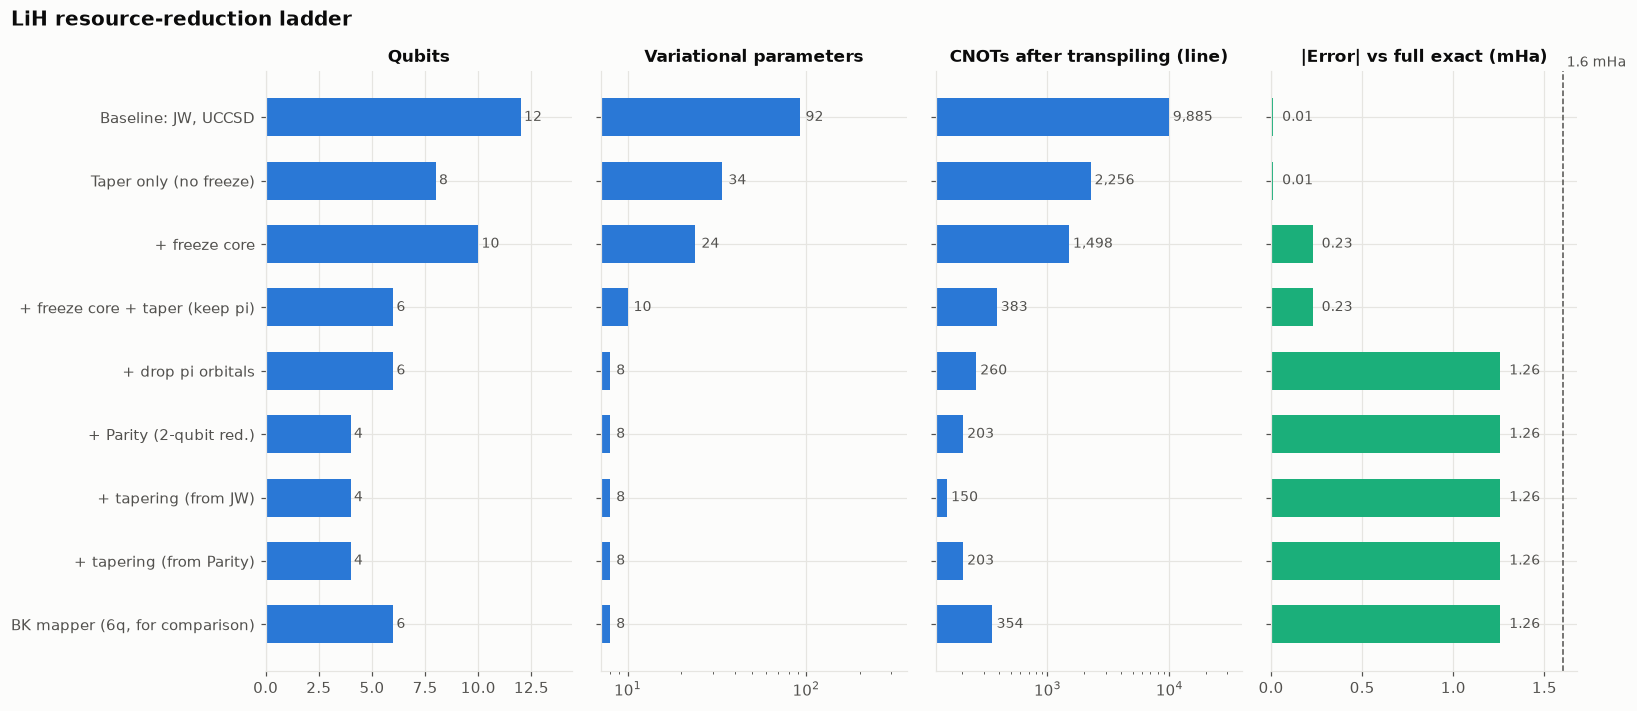

In [4]:
P.fig_ladder(ladder); plt.show()

**Reading the table**

* *Freeze core* (Li 1s) is nearly free: 0.23 mHa for 2 fewer qubits and about 6.6x fewer CNOTs.
* *Taper only* removes 4 qubits at **zero** cost because the symmetry sectors are fixed by the Hartree-Fock state. UCCSD also loses 58 parameters: excitations forbidden by symmetry disappear.
* *Freeze core + taper (keep pi)* is the sweet spot. Spatial reflection symmetry of the linear molecule supplies two extra Z$_2$ symmetries beyond the two particle-number parities.
* *Drop pi orbitals* is the aggressive option: 4 qubits and 150 CNOTs, but 1.26 mHa of truncation error.
* On the 6 to 4 qubit problem the mappers give the identical energy; they differ only in circuit cost (JW-tapered 150 CNOTs < Parity 203 < BK 354 at 6q).

A live check of the tapering lever:

In [5]:
s = rr.build_setup(rr.Config("live", freeze_core=True, mapper="jw+taper"))
print("qubits:", s.n_qubits, "| UCCSD params:", s.n_params, "| Pauli terms:", rr.operator_metrics(s.qubit_op)["n_pauli"])
out = rr.run_vqe_exact(s)
print(f"VQE energy {out['energy']:.6f} Ha   error vs FULL exact {1e3*(out['energy']-ref):.3f} mHa   ({out['nit']} SLSQP iterations)")

qubits: 6 | UCCSD params: 10 | Pauli terms: 230


VQE energy -7.882175 Ha   error vs FULL exact 0.227 mHa   (9 SLSQP iterations)


## Phase 3: make the circuit shorter

With the qubit count fixed we compare ansaetze on transpiled CNOT count vs error (4-qubit model first, then the 6-qubit keep-pi model).

In [6]:
an = P.load("ansatz")["rows"]
pd.DataFrame(an)[["name","qubits","params","cx_a2a","cx_line","depth_line","err_vs_active_mHa","err_vs_full_mHa"]].round(4)

,name,qubits,params,cx_a2a,cx_line,depth_line,err_vs_active_mHa,err_vs_full_mHa
0,UCCSD,4,8,55,203,351,0.0000,1.2569
1,SUCCD,4,3,35,152,245,2.3758,3.6327
2,PUCCD,4,2,24,94,163,4.4696,5.7264
3,"HWE (EfficientSU2, reps=1)",4,16,3,3,15,2.4796,3.7365
4,"HWE (EfficientSU2, reps=2)",4,24,6,6,22,0.0173,1.2741
5,"HWE (EfficientSU2, reps=3)",4,32,9,9,29,0.0000,1.2569
6,ADAPT-VQE (UCCSD pool),4,8,57,206,350,0.0000,1.2569


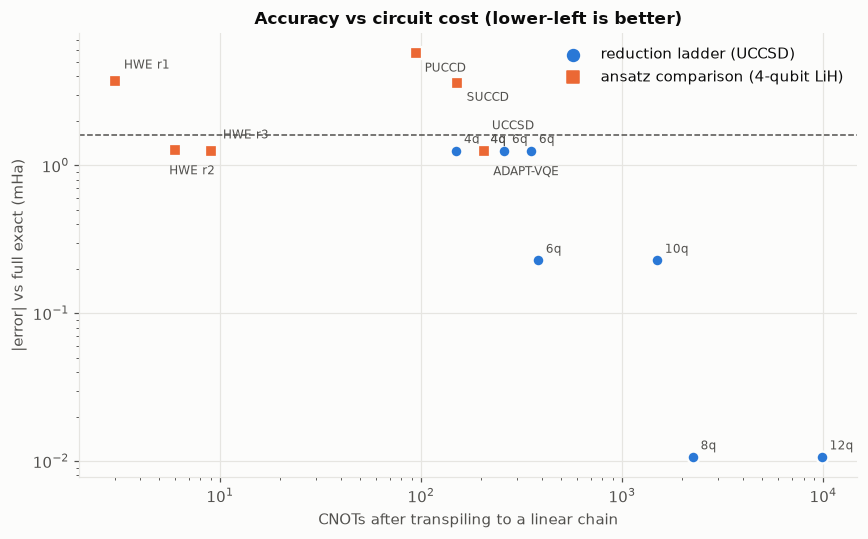

In [7]:
P.fig_pareto(an, ladder); plt.show()

* **SUCCD / PUCCD** have far fewer parameters but cannot represent the ground state (2.4 / 4.5 mHa above the active-space exact energy), so they are not usable.
* **ADAPT-VQE** selected all 8 UCCSD operators, so no saving is available for this tiny system. It only becomes interesting for larger pools.
* **Hardware-efficient (EfficientSU2) on 4 qubits** reaches the exact active-space energy with **9 CNOTs vs 203** for UCCSD. Fewer than 2 layers get stuck above it.
* UCCSD CNOT counts are inflated by naive Trotter synthesis of the Pauli rotations; the *relative* comparison is the reliable part.

The same comparison on the more accurate **6-qubit keep-pi** model:

In [8]:
hwe6 = json.load(open("results/hwe_keep_pi.json"))
uccsd6 = [r for r in ladder if r["name"].startswith("1b")][0]
tab = pd.DataFrame(hwe6)[["name","qubits","params","cx_line","depth_line","err_vs_full_mHa"]]
tab.loc[len(tab)] = ["UCCSD (tapered) on 6q keep-pi", 6, uccsd6["params"], uccsd6["cx_line"], uccsd6["depth_line"], uccsd6["vqe_err_vs_full_mHa"]]
tab.round(3)

,name,qubits,params,cx_line,depth_line,err_vs_full_mHa
0,HWE reps=1 on 6q keep-pi,6,24,5,15,18.750
1,HWE reps=2 on 6q keep-pi,6,36,10,22,18.559
2,HWE reps=3 on 6q keep-pi,6,48,15,29,2.340
3,HWE reps=4 on 6q keep-pi,6,60,20,36,0.409
4,UCCSD (tapered) on 6q keep-pi,6,10,383,505,0.227


**HWE with 4 layers on the 6-qubit model: 20 CNOTs and 0.41 mHa**, versus 383 CNOTs and 0.23 mHa for UCCSD, about 19x shorter and still inside the chemical-accuracy budget. Caveat: it has 60 parameters and needs random restarts (1-2 layers stall near Hartree-Fock, 3 layers reach only 2.3 mHa). That costs more energy evaluations; on a noiseless simulator it is cheap, on hardware it is a real cost.

## Phase 4: reduce the measurements

Two questions: (a) how many shots does *one* energy estimate need for a 1.6 mHa standard error, with and without grouping qubit-wise-commuting Pauli terms (variance-optimal allocation, computed exactly from the optimised state), and (b) what happens in a full shot-noise VQE at a fixed total budget.

In [9]:
sa = P.load("shots_analytic")["rows"]
pd.DataFrame(sa)[["name","qubits","n_pauli","n_groups_qwc","n_groups_gc","shots_ungrouped","shots_qwc","shots_l1_bound"]]

,name,qubits,n_pauli,n_groups_qwc,n_groups_gc,shots_ungrouped,shots_qwc,shots_l1_bound
0,JW 6q (drop pi),6,117,29,14,7.703163e+05,95215.600231,3.668742e+06
1,BK 6q (drop pi),6,117,38,14,7.703163e+05,296444.513854,3.668742e+06
2,Parity 4q (drop pi),4,99,25,14,7.235663e+05,287938.381850,3.565843e+06
3,Tapered 4q (drop pi),4,99,25,14,7.235663e+05,128295.597032,3.565843e+06
4,Tapered 6q (keep pi),6,230,38,24,3.111259e+06,416954.576947,2.957285e+07


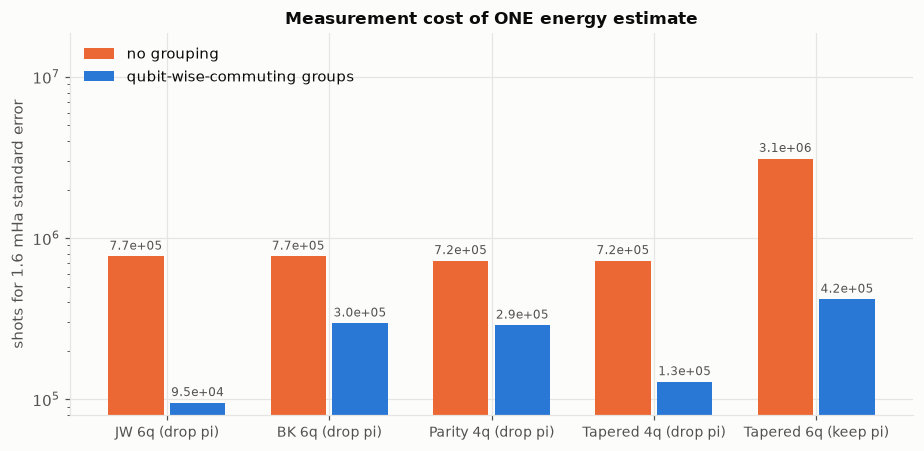

In [10]:
P.fig_shots_analytic(sa); plt.show()

The sampler was validated first: the group statistics reproduce the exact energy to 6 digits, and sampled means agree within statistical error.

Now full VQE with SPSA (120 iterations, decaying gains, averaged tail iterates; 4 seeds), at total budgets 1e5 to 1e8 shots. Error is always against the full exact energy, evaluated noiselessly at the final parameters.

In [11]:
sv = P.load("shots_vqe")["runs"]
df = pd.DataFrame(sv)
df.pivot_table(index=["config","grouping"], columns="budget", values="err_mean_mHa").round(2)

budget                         100000.0     1000000.0    10000000.0   100000000.0
config               grouping                                                    
JW 6q (drop pi)      none            23.60        16.67         2.39         1.51
                     qwc             13.22         2.48         1.58         1.37
Tapered 4q (drop pi) none            35.82        12.68         1.97         1.57
                     qwc             15.91         5.55         1.69         1.43
Tapered 6q (keep pi) none           111.81        45.83        11.12         1.23
                     qwc             80.56        13.14         1.51         0.95

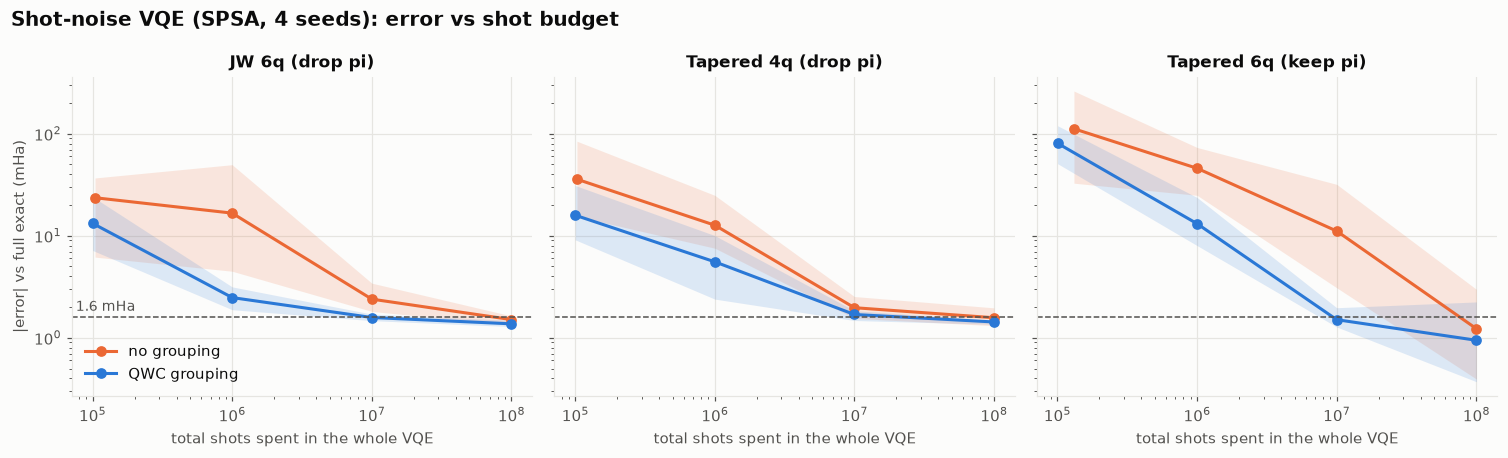

In [12]:
P.fig_shots_vqe(sv); plt.show()

**Under a fixed budget of 1e7 shots** only the 6-qubit keep-pi model with QWC grouping gets below 1.6 mHa (1.5 mHa). The 4-qubit and 6-qubit drop-pi models are stuck just above because their 1.26 mHa truncation error leaves only 0.34 mHa for everything else. Grouping is worth about one decade of shots at equal accuracy. Fewer qubits did **not** automatically mean fewer shots: the keep-pi model has more Pauli terms but a much smaller truncation penalty.

## Phase 5: does the reduced model stay accurate (PES), and a bigger molecule (BeH$_2$)

**LiH potential energy curve** with the 4-qubit model:

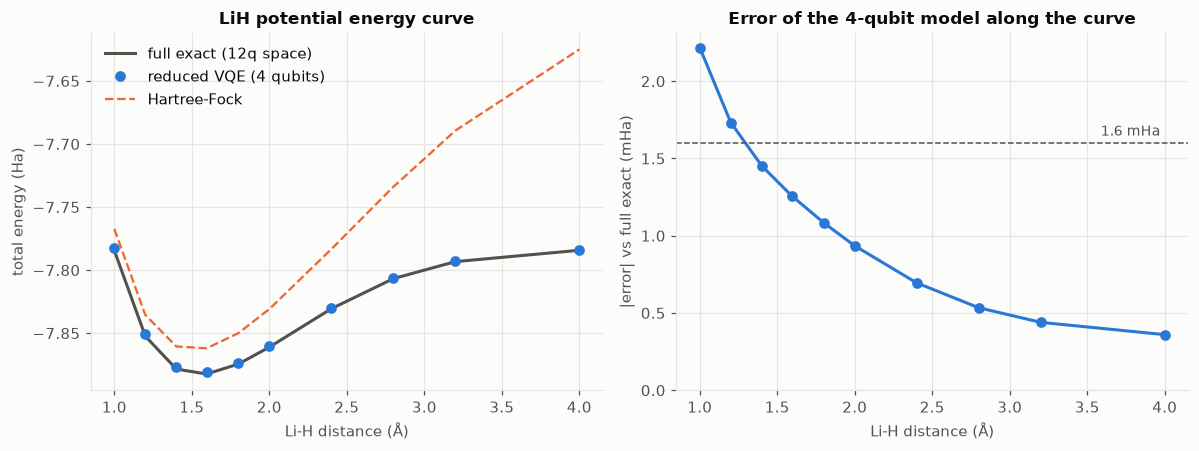

In [13]:
pes = P.load("pes")["rows"]
P.fig_pes(pes); plt.show()

The 4-qubit model is fine at and beyond equilibrium (error shrinks to 0.36 mHa at 4 A) but **exceeds 1.6 mHa for bond lengths below about 1.3 A**, because the pi orbitals matter more when the atoms are compressed. This is purely a truncation effect: VQE reproduces the reduced-space exact energy to better than 1e-4 mHa everywhere.

**BeH$_2$** (7 spatial orbitals, 14 qubits unreduced), same ladder:

In [14]:
beh = P.load("beh2")["rows"]
beh = sorted(beh, key=lambda r: order.index(r["name"][:2]))
P.ladder_table(beh).round(3)

,configuration,qubits,params,Pauli terms,QWC groups,CNOT (all-to-all),CNOT (line),depth (line),truncation (mHa),VQE error vs FULL exact (mHa)
0,"0 Baseline: JW, UCCSD",14,204,665,140,2358,30798,36950,0.000,NaN
1,A Taper only (no freeze),9,38,595,102,677,3101,3974,0.000,NaN
2,1 + freeze core,12,92,326,53,1019,9885,12498,0.339,NaN
3,1b + freeze core + taper (keep pi),7,18,267,56,257,1065,1436,0.339,0.710
4,2 + drop pi orbitals,8,26,184,46,265,1583,2372,5.669,5.703
5,3 + Parity (2-qubit red.),6,26,164,34,422,1342,1975,5.669,5.703
6,4a + tapering (from JW),5,14,131,34,151,385,714,5.669,5.703
7,4b + tapering (from Parity),5,14,131,29,173,431,663,5.669,5.703
8,"5 BK mapper (6q, for comparison)",8,26,184,34,503,2169,2728,5.669,5.703


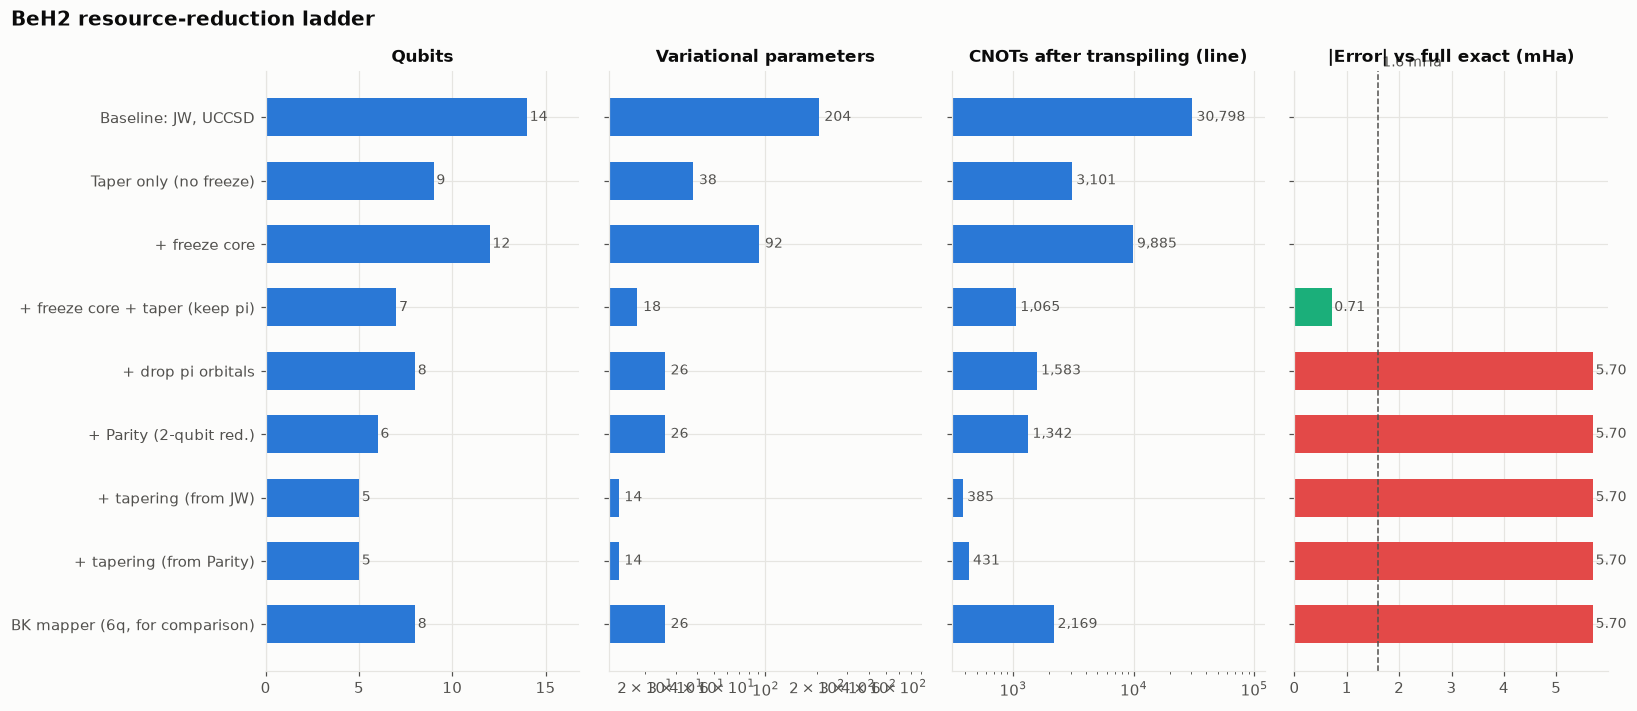

In [15]:
P.fig_ladder(beh, title="BeH2 resource-reduction ladder"); plt.show()

For BeH$_2$ the trend is sharper: **dropping the pi orbitals costs 5.7 mHa and fails chemical accuracy**, while **freeze core + tapering (keep pi) takes 14 to 7 qubits with 0.71 mHa total error** (0.34 mHa truncation + 0.37 mHa because UCCSD omits triples/quadruples). The 14-qubit baseline needs 30,798 CNOTs on a line.

## Recommendation

* **Default choice (best accuracy per resource): freeze core + Z$_2$ tapering, keep the pi orbitals, JW-tapered mapper, qubit-wise-commuting grouping.** 12 to 6 qubits (LiH) and 14 to 7 (BeH$_2$), chemical accuracy at the geometries tested, and the only LiH model that passes at a 1e7-shot budget.
* **If circuit depth is the binding constraint:** keep that model but swap UCCSD for a 4-layer hardware-efficient ansatz (20 CNOTs vs 383).
* **If qubits are the binding constraint and the molecule stays near equilibrium:** drop pi orbitals to reach 4 qubits, accepting 1.26 mHa up front. Do *not* do this for BeH$_2$ or compressed geometries.

## Caveats

* All results are noiseless statevector simulations. Shot noise is simulated exactly from the state; gate/readout noise and error mitigation are **not** modelled.
* CNOT counts use Qiskit's default Pauli-evolution synthesis, `optimization_level=3`, seed 7; a linear chain stands in for hardware connectivity.
* The 14-qubit BeH$_2$ baseline has circuit metrics only (no VQE run); no BeH$_2$ shot-noise runs were done.
* The hardware-efficient ansatz does not conserve particle number by construction; its results were compared with the sector-restricted exact energy of the same active space.
* SPSA hyper-parameters (`step0=0.03`, `c=0.1`) were tuned on the 4-qubit model and reused unchanged elsewhere.
* `results/hwe_keep_pi.json` came from a one-off script (not part of `run_experiments.py`).

## Reproduce

```
pip install qiskit qiskit-aer qiskit-nature pyscf qiskit-algorithms matplotlib pandas
python run_experiments.py ladder ladder_extra ansatz shots pes beh2   # about 20 min, writes results/*.json
```